# Tutorial: turning a disaster-response problem into a QUBO and solving it with QAOA

This notebook walks through QuRescue step by step. You can swap in your own drones, requests and objectives.

## 1. The situation
Drones (medical, cargo, sensor) and help requests (medical, stranded, supply, gas leak, survey), each with a location, urgency and number of people.

In [1]:
from qurescue.scenario import make_scenario, escalate
sc = make_scenario('flood')
for d in sc.drones: print('drone', d.id, d.kind)
for r in sc.requests: print('request', r.id, r.kind, r.label, 'urgency', r.urgency, 'people', r.people)

drone 0 medical
drone 1 cargo
drone 2 cargo
drone 3 sensor
request 0 medical Injured man, Village A urgency 0.95 people 1
request 1 medical Fever cases, relief camp 2 urgency 0.55 people 2
request 2 stranded Family on rooftop urgency 0.85 people 6
request 3 stranded People on embankment urgency 0.7 people 4
request 4 supply Village B: no clean water urgency 0.4 people 200
request 5 supply Village C: food running out urgency 0.35 people 150
request 6 gas_leak Exposed gas main, near homes urgency 0.7 people 50
request 7 survey Unknown: check for survivors urgency 0.3 people 0


## 2. Binary variables, with domain pruning
`x[r,d] = 1` if drone *d* serves request *r*. A variable is only created if the drone carries the right payload and can make the round trip. Every pruned pair is one qubit saved.

In [2]:
from qurescue.qubo import build_qubo
model = build_qubo(sc, alpha=0.6)
print(len(sc.requests)*len(sc.drones), 'naive variables ->', model.n, 'qubits after pruning')
print(model.pairs)

32 naive variables -> 14 qubits after pruning
[(6, 3), (5, 1), (5, 2), (2, 0), (2, 1), (2, 2), (0, 0), (4, 1), (4, 2), (3, 0), (3, 1), (3, 2), (1, 0), (7, 3)]


## 3. Competing objectives in one cost function
$$\min\; -\sum_k b_k x_k + P\sum_{(k,l)\,\text{conflict}} x_k x_l$$
Benefit $b = \alpha\cdot\text{urgency} + (1-\alpha)\cdot\text{people} - \lambda\cdot\text{distance}$. The slider $\alpha$ moves between *most people helped* (0) and *most critical first* (1).

The constraints (one request per drone, one drone per request) are **pairwise penalties**, so no extra slack qubits are needed.

In [3]:
import numpy as np
print('penalty P =', round(model.penalty,3))
print('non-zero quadratic terms:', int((model.Q!=0).sum()))

penalty P = 1.334
non-zero quadratic terms: 27


## 4. QUBO to Ising Hamiltonian
Substitute $x_i = (1-Z_i)/2$. The lowest-energy state of this Hamiltonian is the best dispatch plan.

In [4]:
from qurescue.qubo import to_ising
H, scale, const = to_ising(model)
print(H.num_qubits, 'qubits,', len(H), 'Pauli terms')
print(H[:5])

14 qubits, 41 Pauli terms
SparsePauliOp(['IIIIIIIIIIIIIZ', 'IIIIIIIIIIIIZI', 'IIIIIIIIIIIZII', 'IIIIIIIIIIZIII', 'IIIIIIIIIZIIII'],
              coeffs=[-0.01664413+0.j, -0.72750763+0.j, -0.72801603+0.j, -0.9555233 +0.j,
 -0.95740419+0.j])


## 5. Ground truth and a classical baseline

In [5]:
from qurescue.solvers import brute_force, greedy, assignment
bf = brute_force(model); gr = greedy(model)
print('optimal cost', round(bf['cost'],3), assignment(model, bf['x']))
print('greedy  cost', round(gr['cost'],3), assignment(model, gr['x']))

optimal cost -1.983 [(6, 3), (5, 2), (2, 1), (0, 0)]
greedy  cost -1.949 [(6, 3), (5, 1), (2, 0), (4, 2)]


## 6. QAOA in Qiskit

In [6]:
from qurescue.solvers import qaoa
res = qaoa(model, reps=2, seed=1, optimum_cost=bf['cost'])
print('QAOA cost', round(res['cost'],3), '| optimal?', abs(res['cost']-bf['cost'])<1e-9, '| evaluations', res['nfev'])

QAOA cost -1.983 | optimal? True | evaluations 200


## 7. The situation changes: warm-start re-planning
Water rises and urgencies shift. Instead of random angles, start from the angles that solved the previous plan.

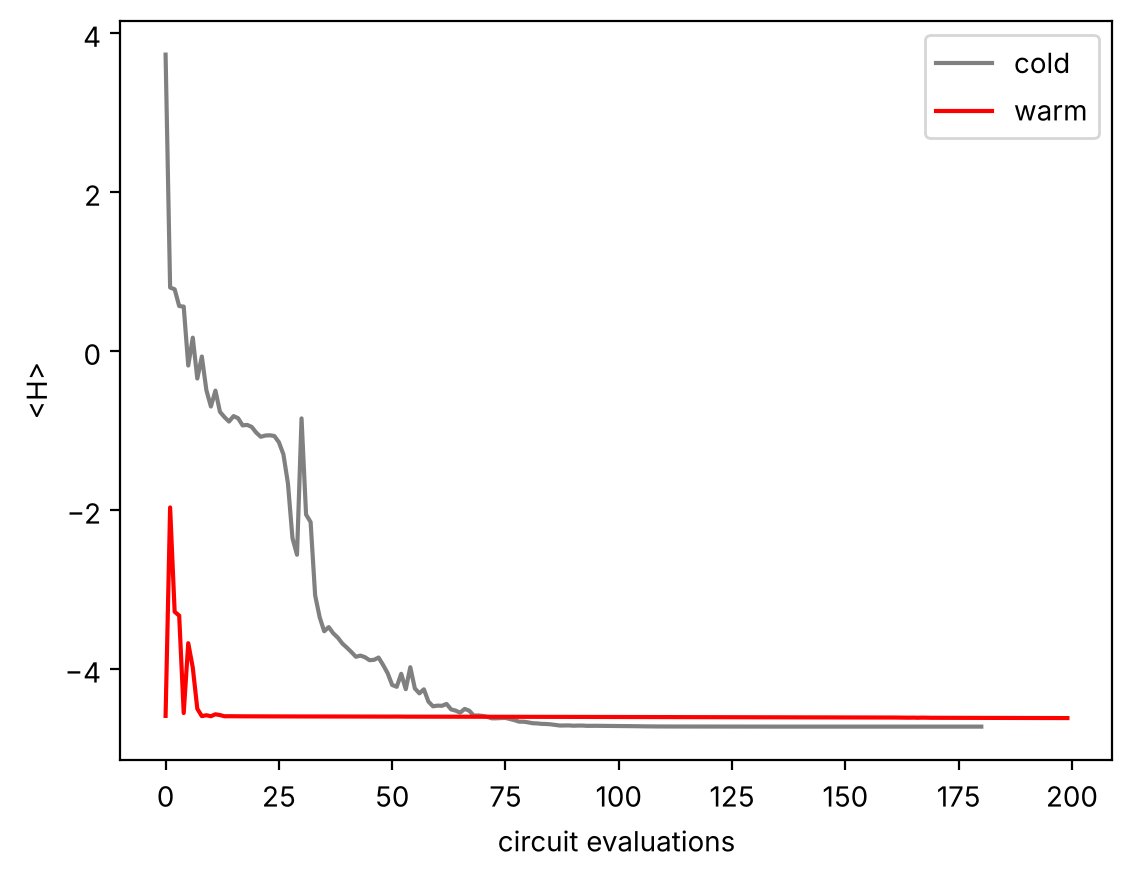

warm optimal? True | cold optimal? True


In [7]:
sc2 = escalate(sc, seed=101); m2 = build_qubo(sc2, alpha=0.6); bf2 = brute_force(m2)
warm = qaoa(m2, reps=2, init_params=res['params'], optimum_cost=bf2['cost'])
cold = qaoa(m2, reps=2, seed=5, optimum_cost=bf2['cost'])
import matplotlib.pyplot as plt
plt.plot(cold['history'], c='gray', label='cold'); plt.plot(warm['history'], c='red', label='warm')
plt.xlabel('circuit evaluations'); plt.ylabel('<H>'); plt.legend(); plt.show()
print('warm optimal?', abs(warm['cost']-bf2['cost'])<1e-9, '| cold optimal?', abs(cold['cost']-bf2['cost'])<1e-9)

## 8. Try it yourself
- Change `alpha` and watch the plan change.
- Add a new request type to `COMPAT` in `scenario.py`.
- Run `python run_on_ibm.py --mode border` to execute on real IBM hardware.